# Task 04: Supervised Classification Modeling & Hyperparameter Tuning

**Internship:** RabTech Academy

## Objective
To train and compare multiple supervised machine learning models, optimise their hyperparameters using cross-validation, evaluate their performance, and select the best-performing model.

## Dataset
UCI Adult Income Dataset

## Algorithms
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# Save model
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Define column names
columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "income"
]

# Dataset URLs
train_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
test_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

# Load training data
train_df = pd.read_csv(
    train_url,
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

# Load testing data
test_df = pd.read_csv(
    test_url,
    names=columns,
    skipinitialspace=True,
    na_values="?",
    skiprows=1
)

# Combine datasets
df = pd.concat([train_df, test_df], ignore_index=True)

# Clean target labels
df["income"] = df["income"].str.strip().str.replace(
    r"\.$", "", regex=True
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# Dataset overview

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (48842, 15)

Column Names:
['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

Data Types:
age               int64
workclass           str
fnlwgt            int64
education           str
education_num     int64
marital_status      str
occupation          str
relationship        str
race                str
sex                 str
capital_gain      int64
capital_loss      int64
hours_per_week    int64
native_country      str
income              str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       46043 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-nul

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000



First 5 Records:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check target distribution
print("\nIncome Distribution:")
print(df["income"].value_counts())

Missing Values:
age                  0
workclass         2799
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     857
income               0
dtype: int64

Total Missing Values: 6465

Duplicate Records: 52

Income Distribution:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64


In [5]:
# Convert income into binary values
# 0 = Income <=50K
# 1 = Income >50K

y = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

# Separate input features
X = df.drop("income", axis=1)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget values:")
print(y.head())

Features shape: (48842, 14)
Target shape: (48842,)

Target distribution:
income
0    37155
1    11687
Name: count, dtype: int64

Target values:
0    0
1    0
2    0
3    0
4    0
Name: income, dtype: int64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (39073, 14)
Testing data: (9769, 14)
Training target: (39073,)
Testing target: (9769,)


In [7]:
# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical Features:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


C:\Users\Administrator\AppData\Local\Temp\ipykernel_13128\2003934618.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [8]:
# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Both preprocessing pipelines created successfully!")

Both preprocessing pipelines created successfully!


In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("ColumnTransformer created successfully!")

ColumnTransformer created successfully!


In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

print("Four machine learning models defined successfully!")

for name in models:
    print(name)

Four machine learning models defined successfully!
Logistic Regression
Decision Tree
Random Forest
Gradient Boosting


In [11]:
results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    print("Training:", name)

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(name, "completed!\n")

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    )
)

Training: Logistic Regression
Logistic Regression completed!

Training: Decision Tree
Decision Tree completed!

Training: Random Forest
Random Forest completed!

Training: Gradient Boosting
Gradient Boosting completed!



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Gradient Boosting,0.869895,0.796884,0.612489,0.692624,0.923716
2,Random Forest,0.856485,0.735412,0.625321,0.675913,0.903667
0,Logistic Regression,0.850650,0.731438,0.594098,0.655653,0.904222
1,Decision Tree,0.810216,0.601086,0.615483,0.608199,0.743458


In [12]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified 5-Fold Cross-Validation created successfully!")

Stratified 5-Fold Cross-Validation created successfully!


In [ ]:
# Random Forest pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

# Hyperparameter grid
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [10, 20, None],
    "classifier__min_samples_split": [2, 5]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

# Fit Grid Search
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


In [ ]:
# Retrieve the best tuned model
best_model = grid_search.best_estimator_

# Generate predictions
y_pred_tuned = best_model.predict(X_test)

# Generate prediction probabilities
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

print("Best tuned model selected successfully!")

In [18]:
print("Tuned Random Forest Model Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1 Score:", f1_score(y_test, y_pred_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

Tuned Random Forest Model Performance
Accuracy: 0.8609888422561163
Precision: 0.74822695035461
Recall: 0.6317365269461078
F1 Score: 0.685064935064935
ROC-AUC: 0.9104252133601186

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.93      0.91      7431
           1       0.75      0.63      0.69      2338

    accuracy                           0.86      9769
   macro avg       0.82      0.78      0.80      9769
weighted avg       0.86      0.86      0.86      9769



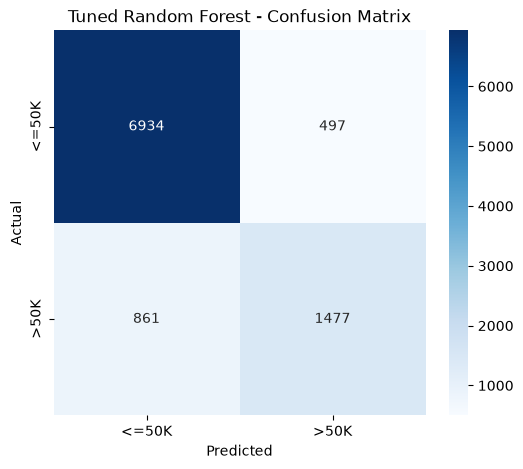

In [19]:
cm = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)

plt.title("Tuned Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [20]:
# Store fitted models for ROC curve comparison

fitted_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

# Add tuned Random Forest
fitted_models["Tuned Random Forest"] = best_model

print("All fitted models are ready for ROC analysis!")

All fitted models are ready for ROC analysis!


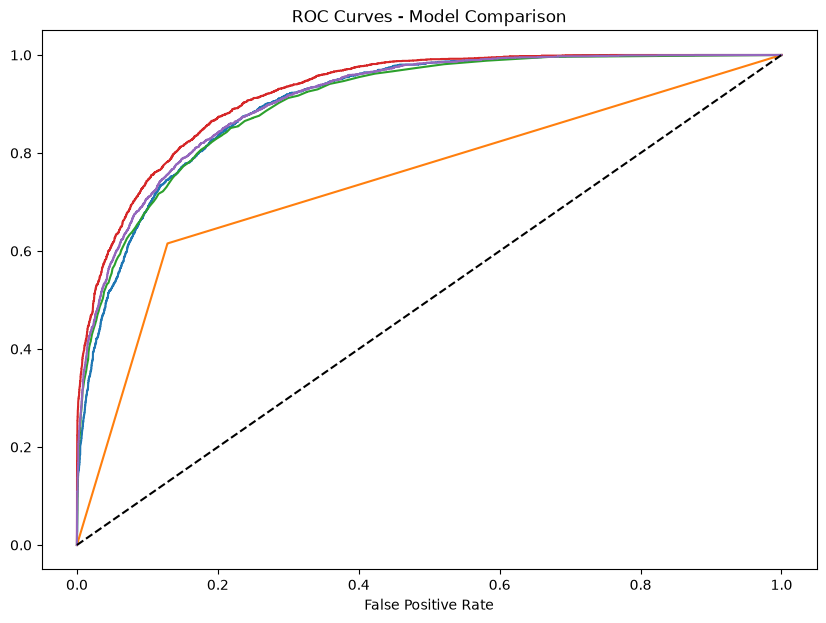

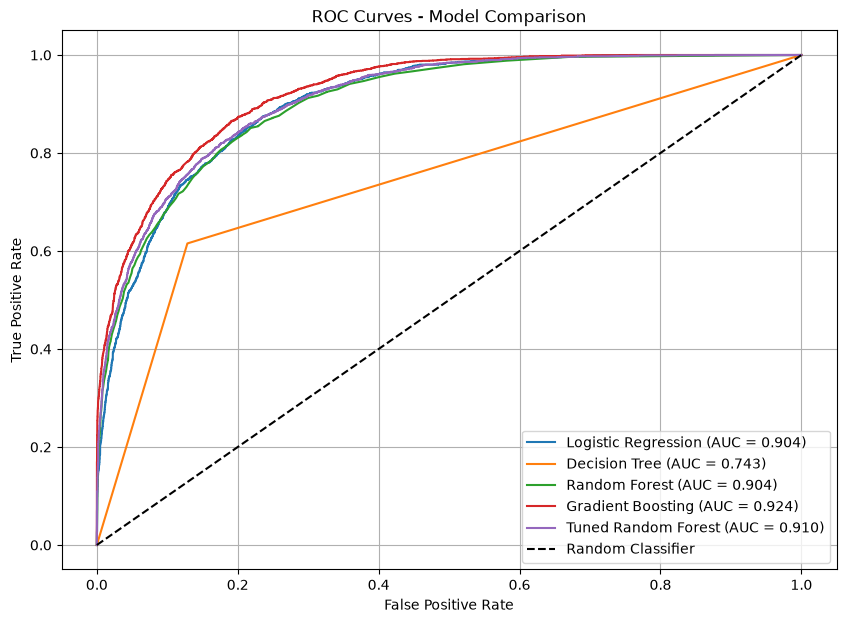

C:\Users\Administrator\AppData\Local\Temp\ipykernel_13128\1372944276.py:48: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


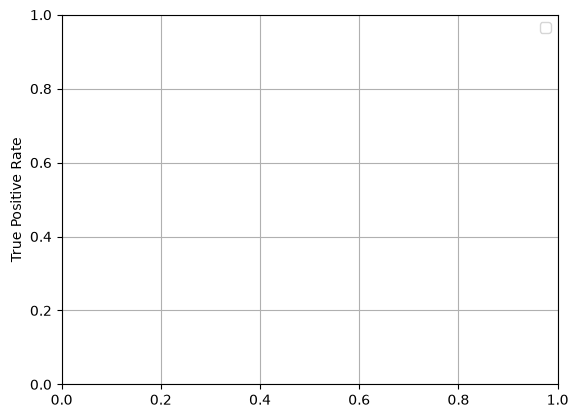

In [22]:
plt.figure(figsize=(10, 7))

for name, model in fitted_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("ROC Curves - Model Comparison")
plt.xlabel("False Positive Rate")
plt.figure(figsize=(10, 7))

for name, model in fitted_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("ROC Curves - Model Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid()
plt.show()
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid()
plt.show()

In [23]:
final_results = []

for name, model in fitted_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

final_results_df = pd.DataFrame(final_results)

final_results_df = final_results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(final_results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Gradient Boosting,0.869895,0.796884,0.612489,0.692624,0.923716
4,Tuned Random Forest,0.860989,0.748227,0.631737,0.685065,0.910425
2,Random Forest,0.856485,0.735412,0.625321,0.675913,0.903667
0,Logistic Regression,0.850650,0.731438,0.594098,0.655653,0.904222
1,Decision Tree,0.810216,0.601086,0.615483,0.608199,0.743458


In [24]:
best_model_name = final_results_df.iloc[0]["Model"]

if best_model_name == "Tuned Random Forest":
    selected_model = best_model
else:
    selected_model = fitted_models[best_model_name]

print("Best Model:", best_model_name)

print("\nBest Model Performance:")
display(final_results_df.head(1))

Best Model: Gradient Boosting

Best Model Performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Gradient Boosting,0.869895,0.796884,0.612489,0.692624,0.923716


In [25]:
import joblib

joblib.dump(
    selected_model,
    "RabTech_Task04_Best_Model.joblib"
)

print("Best model saved successfully!")

Best model saved successfully!
